In [1]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
number_of_realisations = 50
surface_temperature = 1800  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25 
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [5]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


idealspecies_withsols = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

realspecies_withsols = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

## Oxygen fugacity



In [88]:
# Vary Linearly:
fO2_log10_shifts = np.linspace(-6, 0, number_of_realisations)  # IW-6 to IW


# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(number_of_realisations, 0)  # 1% of planet mass
log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar

h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}

In [20]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [21]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyfO2_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyfO2_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyfO2_withsol = model_ideal_varyfO2_withsol.output

# Write the complete solution to Excel
output_ideal_varyfO2_withsol.to_excel("A_FINAL_TEST_FO2_IDEAL")

# Write the data to a pickle file with dataframes
output_ideal_varyfO2_withsol.to_pickle("A_FINAL_TEST_FO2_IDEAL")

[13:38:04 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[13:38:04 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:38:04 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[13:38:04 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[13:38:04 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[13:38:04 - atmodeller.classes             - INFO     ] - Solver steps (max) = 37
[13:38:04 - atmodeller.output              - INFO     ] - Writing output to excel
[13:38:04 - a

In [22]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyfO2_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyfO2_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyfO2_withsol.log_number_density,
)
A_FINAL_TEST_FO2_REAL = model_real_varyfO2_withsol.output

# Write the complete solution to Excel
A_FINAL_TEST_FO2_REAL.to_excel("A_FINAL_TEST_FO2_REAL")

# Write the data to a pickle file with dataframes
A_FINAL_TEST_FO2_REAL.to_pickle("A_FINAL_TEST_FO2_REAL")

[13:38:05 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[13:38:05 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:38:05 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[13:38:05 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[13:38:05 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[13:38:05 - atmodeller.classes             - INFO     ] - Solver steps (max) = 22
[13:38:05 - atmodeller.output              - INFO    

In [89]:

output_df = A_FINAL_TEST_FO2_REAL.to_dataframes()

pressure = output_df["atmosphere"]["pressure"]
pressure_GPa = pressure * 1e-4

fugacity_coefficientH2 = output_df["H2_g"]["fugacity_coefficient"]
fugacity_coefficientH2O = output_df["H2O_g"]["fugacity_coefficient"]
fugacity_coefficientCO2 = output_df["CO2_g"]["fugacity_coefficient"]
fugacity_coefficientCH4 = output_df["CH4_g"]["fugacity_coefficient"]

dissolved_ppmwH2 = output_df["H2_g"]["dissolved_ppmw"]
dissolved_wtpH2 = dissolved_ppmwH2 * 1e-4  # wt.%

dissolved_ppmwH2O = output_df["H2O_g"]["dissolved_ppmw"]
dissolved_wtpH2O = dissolved_ppmwH2O * 1e-4  # wt.%

dissolved_ppmwCO2 = output_df["CO2_g"]["dissolved_ppmw"]
dissolved_wtpCO2 = dissolved_ppmwCO2 * 1e-4  # wt.%

dissolved_ppmwCH4 = output_df["CH4_g"]["dissolved_ppmw"]
dissolved_wtpCH4 = dissolved_ppmwCH4 * 1e-4  # wt.%



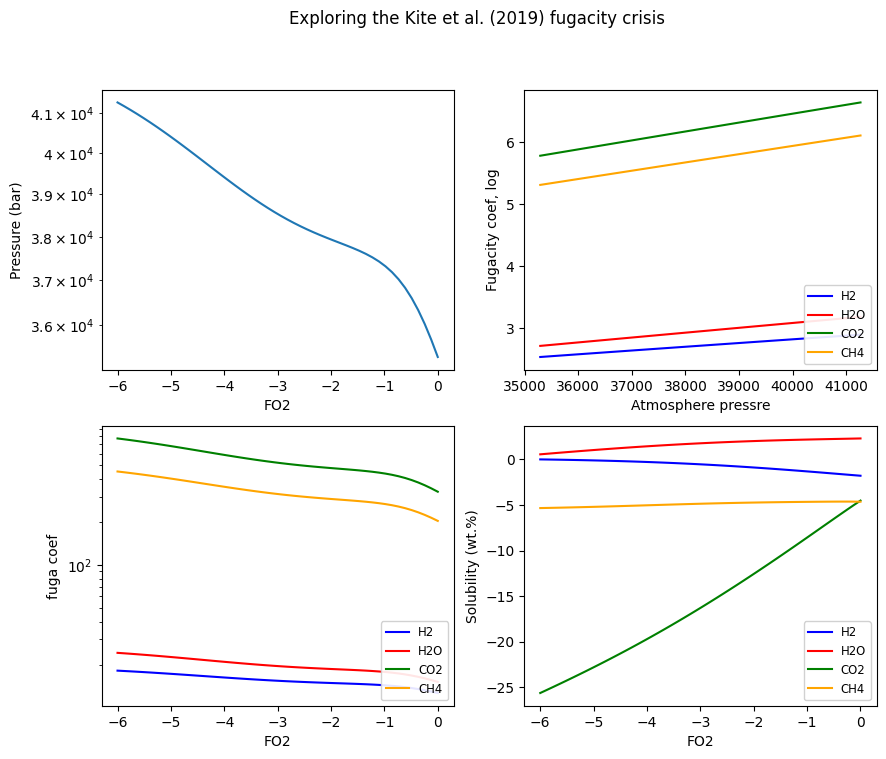

In [90]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

ax = axes[0, 0]
ax.plot(fO2_log10_shifts, pressure)
ax.set_yscale("log")
ax.set_xlabel(r"FO2")
ax.set_ylabel("Pressure (bar)")

ax = axes[1, 0]
ax.plot(fO2_log10_shifts, fugacity_coefficientH2, label='H2', color='blue')
ax.plot(fO2_log10_shifts, fugacity_coefficientH2O, label='H2O', color='red')
ax.plot(fO2_log10_shifts, fugacity_coefficientCO2, label='CO2', color='green')
ax.plot(fO2_log10_shifts, fugacity_coefficientCH4, label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_yscale("log")
ax.set_xlabel("FO2")
ax.set_ylabel("fuga coef")

ax = axes[1, 1]
# Plot solubility as wt.%
ax.plot(fO2_log10_shifts, np.log(dissolved_wtpH2), label='H2', color='blue')
ax.plot(fO2_log10_shifts, np.log(dissolved_wtpH2O), label='H2O', color='red')
ax.plot(fO2_log10_shifts, np.log(dissolved_wtpCO2), label='CO2', color='green')
ax.plot(fO2_log10_shifts, np.log(dissolved_wtpCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"FO2")
ax.set_ylabel("Solubility (wt.%)")

ax = axes[0, 1]
ax.plot(pressure, np.log(fugacity_coefficientH2), label='H2', color='blue')
ax.plot(pressure, np.log(fugacity_coefficientH2O), label='H2O', color='red')
ax.plot(pressure, np.log(fugacity_coefficientCO2), label='CO2', color='green')
ax.plot(pressure, np.log(fugacity_coefficientCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"Atmosphere pressre")
ax.set_ylabel(r"Fugacity coef, log")

fig.suptitle("Exploring the Kite et al. (2019) fugacity crisis")

plt.show()

## Vary Planetary Mass

Planet mass varies from 4 to 9 MEarth, surface radius is fixed at 1.76 REarth

In [268]:

def radius(mass):
    rad = 1.02*(mass**0.252)
    return rad
# For simulations with varying planet mass:

planet_mass_Earths = np.linspace(4, 20, number_of_realisations)  # Vary linearly from 4-9 MEarth
planet_mass = planet_mass_Earths * 5.9722e24

planet_radii_Earths = radius(planet_mass_Earths)
planet_radius = planet_radii_Earths * 6371000

print(planet_radius)

# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(
    number_of_realisations, 0
)  # ~3% of planet mass, used for fix Surf Radius and Planet Mass cases
log10_ch_ratios = np.full(number_of_realisations, -0.58)  # 100X Solar
fO2_log10_shifts = np.full(number_of_realisations, -3)

h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}

[ 9215669.570660109  9399721.83224749   9573658.815841205
  9738691.328274976  9895816.838930674 10045867.676361112
 10189546.211127091 10327451.051145274 10460096.887762938
 10587929.765577437 10711338.99457796  10830666.559041122
 10946214.633133002 11058251.645756586 11167017.220475426
 11272726.233651772 11375572.174471239 11475729.947177263
 11573358.22384113  11668601.432100464 11761591.444266194
 11852449.020452043 11941285.047804935 12028201.609707836
 12113292.912405869 12196646.091445416 12278341.916297646
 12358455.408326393 12437056.384676998 12514209.938572655
 12589976.864803748 12664414.03780423  12737574.748564713
 12809509.005686587 12880263.805096416 12949883.37228579
 13018409.38039365  13085881.146987814 13152335.812013708
 13217808.499049276 13282332.461725347 13345939.216932183
 13408658.666229082 13470519.206698585 13531547.832336443
 13591770.22693818  13651210.849330764 13709893.011699988
 13767838.951679422 13825069.898792429]


In [181]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [182]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyMp_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyMp_withsol = model_ideal_varyMp_withsol.output

# Write the complete solution to Excel
output_ideal_varyMp_withsol.to_excel("A_FINAL_TEST_MASS_IDEAL")

# Write the data to a pickle file with dataframes
output_ideal_varyMp_withsol.to_pickle("A_FINAL_TEST_MASS_IDEAL")

[16:14:42 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[16:14:42 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[16:14:42 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[16:14:42 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[16:14:42 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[16:14:42 - atmodeller.classes             - INFO     ] - Solver steps (max) = 32
[16:14:42 - atmodeller.output              - INFO     ] - Writing output to excel
[16:14:42 - a

In [183]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyMp_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyMp_withsol.log_number_density,
)
A_FINAL_TEST_MASS_REAL = model_real_varyMp_withsol.output

# Write the complete solution to Excel
A_FINAL_TEST_MASS_REAL.to_excel("A_FINAL_TEST_MASS_REAL")

# Write the data to a pickle file with dataframes
A_FINAL_TEST_MASS_REAL.to_pickle("A_FINAL_TEST_MASS_REAL")

[16:14:43 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[16:14:43 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[16:14:43 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[16:14:43 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[16:14:43 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[16:14:43 - atmodeller.classes             - INFO     ] - Solver steps (max) = 50
[16:14:43 - atmodeller.output              - INFO    

In [6]:

output_df = A_FINAL_TEST_MASS_REAL.to_dataframes()

pressure = output_df["atmosphere"]["pressure"]
pressure_GPa = pressure * 1e-4

fugacity_coefficientH2 = output_df["H2_g"]["fugacity_coefficient"]
fugacity_coefficientH2O = output_df["H2O_g"]["fugacity_coefficient"]
fugacity_coefficientCO2 = output_df["CO2_g"]["fugacity_coefficient"]
fugacity_coefficientCH4 = output_df["CH4_g"]["fugacity_coefficient"]

fugacityH2 = output_df["H2_g"]["fugacity"]
fugacityH2O = output_df["H2O_g"]["fugacity"]
fugacityCO2 = output_df["CO2_g"]["fugacity"]
fugacityCH4 = output_df["CH4_g"]["fugacity"]

element_H = output_df["element_H"]["atmosphere_ppmw"] * 10**-4
element_O = output_df["element_O"]["atmosphere_ppmw"] * 10**-4
element_C = output_df["element_C"]["atmosphere_ppmw"] * 10**-4
element_N = output_df["element_N"]["atmosphere_ppmw"] * 10**-4

ratio_H_C = element_H / element_C
ratio_H_O = element_H / element_O
ratio_C_O = element_C / element_O

dissolved_ppmwH2 = output_df["H2_g"]["dissolved_ppmw"]
dissolved_wtpH2 = dissolved_ppmwH2 * 1e-4  # wt.%

dissolved_ppmwH2O = output_df["H2O_g"]["dissolved_ppmw"]
dissolved_wtpH2O = dissolved_ppmwH2O * 1e-4  # wt.%

dissolved_ppmwCO2 = output_df["CO2_g"]["dissolved_ppmw"]
dissolved_wtpCO2 = dissolved_ppmwCO2 * 1e-4  # wt.%

dissolved_ppmwCH4 = output_df["CH4_g"]["dissolved_ppmw"]
dissolved_wtpCH4 = dissolved_ppmwCH4 * 1e-4  # wt.%



atm_ppmwH2 = output_df["H2_g"]["atmosphere_ppmw"]
atm_wtpH2 = atm_ppmwH2 * 1e-4  # wt.%

atm_ppmwH2O = output_df["H2O_g"]["atmosphere_ppmw"]
atm_wtpH2O = atm_ppmwH2O * 1e-4  # wt.%

atm_ppmwCO2 = output_df["CO2_g"]["atmosphere_ppmw"]
atm_wtpCO2 = atm_ppmwCO2 * 1e-4  # wt.%

atm_ppmwCH4 = output_df["CH4_g"]["atmosphere_ppmw"]
atm_wtpCH4 = atm_ppmwCH4 * 1e-4  # wt.%



atm_wtpH2 = atm_ppmwH2 * 1e-4  # wt.%
atm_wtpH2O = atm_ppmwH2O * 1e-4  # wt.%
RATIO_H2_H2O = atm_wtpH2 / atm_wtpH2O

atm_wtpCO2 = atm_ppmwCO2 * 1e-4  # wt.%
atm_wtpCH4 = atm_ppmwCH4 * 1e-4  # wt.%
RATIO_CO2_CH4 = atm_wtpCO2 / atm_wtpCH4

H2_1 = fugacityH2[0]
H2_2 = fugacityH2[49]

H2O_1 = fugacityH2O[0]
H2O_2 = fugacityH2O[49]

CO2_1 = fugacityCO2[0]
CO2_2 = fugacityCO2[49]

CH4_1 = fugacityCH4[0]
CH4_2 = fugacityCH4[49]



K_1 = (CH4_1 * H2O_1**2) / (CO2_1 * H2_1**4)
K_2 = (CH4_2 * H2O_2**2) / (CO2_2 * H2_2**4)

print(K_1 - K_2)


NameError: name 'A_FINAL_TEST_MASS_REAL' is not defined

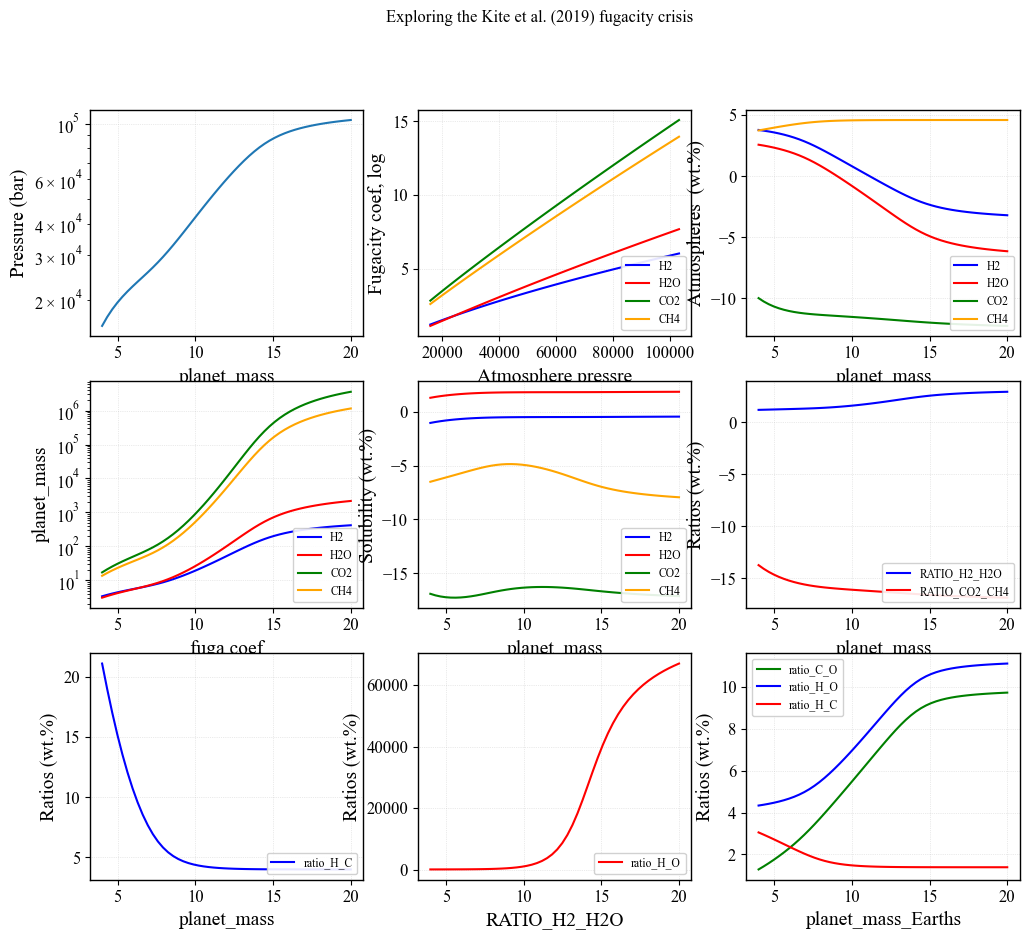

In [278]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10))

ax = axes[0, 0]
ax.plot(planet_mass_Earths, pressure)
ax.set_yscale("log")
ax.set_xlabel(r"planet_mass")
ax.set_ylabel("Pressure (bar)")

ax = axes[1, 0]
ax.plot(planet_mass_Earths, fugacity_coefficientH2, label='H2', color='blue')
ax.plot(planet_mass_Earths, fugacity_coefficientH2O, label='H2O', color='red')
ax.plot(planet_mass_Earths, fugacity_coefficientCO2, label='CO2', color='green')
ax.plot(planet_mass_Earths, fugacity_coefficientCH4, label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_yscale("log")
ax.set_xlabel("fuga coef")
ax.set_ylabel("planet_mass")

ax = axes[1, 1]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, np.log(dissolved_wtpH2), label='H2', color='blue')
ax.plot(planet_mass_Earths, np.log(dissolved_wtpH2O), label='H2O', color='red')
ax.plot(planet_mass_Earths, np.log(dissolved_wtpCO2), label='CO2', color='green')
ax.plot(planet_mass_Earths, np.log(dissolved_wtpCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass")
ax.set_ylabel("Solubility (wt.%)")

ax = axes[0, 1]
ax.plot(pressure, np.log(fugacity_coefficientH2), label='H2', color='blue')
ax.plot(pressure, np.log(fugacity_coefficientH2O), label='H2O', color='red')
ax.plot(pressure, np.log(fugacity_coefficientCO2), label='CO2', color='green')
ax.plot(pressure, np.log(fugacity_coefficientCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"Atmosphere pressre")
ax.set_ylabel(r"Fugacity coef, log")

ax = axes[0, 2]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, np.log(atm_wtpH2), label='H2', color='blue')
ax.plot(planet_mass_Earths, np.log(atm_wtpH2O), label='H2O', color='red')
ax.plot(planet_mass_Earths, np.log(atm_wtpCO2), label='CO2', color='green')
ax.plot(planet_mass_Earths, np.log(atm_wtpCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass")
ax.set_ylabel("Atmospheres  (wt.%)")

ax = axes[1, 2]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, np.log(RATIO_H2_H2O), label='RATIO_H2_H2O', color='blue')
ax.plot(planet_mass_Earths, np.log(RATIO_CO2_CH4), label='RATIO_CO2_CH4', color='red')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass")
ax.set_ylabel("Ratios (wt.%)")

ax = axes[2, 0]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, ratio_H_C, color='blue', label='ratio_H_C')
ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass")
ax.set_ylabel("Ratios (wt.%)")

ax = axes[2, 1]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, ratio_H_O, color='red', label='ratio_H_O')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"RATIO_H2_H2O")
ax.set_ylabel("Ratios (wt.%)")

ax = axes[2, 2]
# Plot solubility as wt.%
ax.plot(planet_mass_Earths, np.log(ratio_C_O), color='green', label='ratio_C_O')
ax.plot(planet_mass_Earths, np.log(ratio_H_O), color='blue', label='ratio_H_O')
ax.plot(planet_mass_Earths, np.log(ratio_H_C), color='red', label='ratio_H_C')


ax.legend(fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass_Earths")
ax.set_ylabel("Ratios (wt.%)")


fig.suptitle("Exploring the Kite et al. (2019) fugacity crisis")

plt.show()

In [263]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib import colormaps
import numpy as np
import pandas as pd

# ===========================================================
# MASTER NATURE-STYLE LAYOUT
# ===========================================================
def set_master_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"]        = "serif"
    plt.rcParams["font.serif"]         = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"]     = 14
    plt.rcParams["xtick.labelsize"]    = 12
    plt.rcParams["ytick.labelsize"]    = 12
    plt.rcParams["legend.fontsize"]    = 11
    plt.rcParams["axes.linewidth"]     = 1.0
    plt.rcParams["axes.grid"]          = True
    plt.rcParams["grid.linestyle"]     = ":"
    plt.rcParams["grid.linewidth"]     = 0.5
    plt.rcParams["grid.alpha"]         = 0.5
    plt.rcParams["axes.prop_cycle"]    = plt.cycler(color=colormaps["tab10"].colors)

def apply_secondary_gpa_axis(ax):
    def bar_to_gpa(x): return x * 1e-4
    def gpa_to_bar(x): return x * 1e4
    ax2 = ax.secondary_yaxis('right', functions=(bar_to_gpa, gpa_to_bar))
    ax2.set_ylabel("Partial pressure  [GPa]")
    ax2.yaxis.set_major_locator(ticker.LogLocator(base=10))
    ax2.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
    return ax2

def apply_master_layout(fig, ax, title):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(ticker.LogLocator(base=10))
    ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
    fig.suptitle(title, fontsize=20, ha="center", x=0.52, y=0.95)
    ax.legend(
        frameon=True,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5)
    )

# ===========================================================
# EXTRACT FROM YOUR DATAFRAMES
# ===========================================================
output_df = A_FINAL_TEST_MASS_REAL.to_dataframes()

planet_mass_Earths = output_df["planet"]["planet_mass"]

pressure = output_df["atmosphere"]["pressure"]
pressure_GPa = pressure * 1e-4

# Dissolved species
dissolved_wtpH2  = output_df["H2_g"]["dissolved_ppmw"]  * 1e-4
dissolved_wtpH2O = output_df["H2O_g"]["dissolved_ppmw"] * 1e-4
dissolved_wtpCO  = output_df["CO_g"]["dissolved_ppmw"]  * 1e-4
dissolved_wtpCO2 = output_df["CO2_g"]["dissolved_ppmw"] * 1e-4
dissolved_wtpCH4 = output_df["CH4_g"]["dissolved_ppmw"] * 1e-4

# Atmospheric elemental abundances
element_H = output_df["element_H"]["atmosphere_moles"] 
element_O = output_df["element_O"]["atmosphere_moles"]
element_C = output_df["element_C"]["atmosphere_moles"]

ratio_H_C = element_H / element_C
ratio_H_O = element_H / element_O
ratio_C_O = element_C / element_O

element_H = output_df["element_H"]["atmosphere_moles"] / output_df["element_H"]["total_moles"]
element_O = output_df["element_O"]["atmosphere_moles"] / output_df["element_O"]["total_moles"]
element_C = output_df["element_C"]["atmosphere_moles"] / output_df["element_C"]["total_moles"]

X_TICKS = np.arange(4, 21, 1)

def set_x_ticks(ax):
    ax.set_xticks(X_TICKS)
    ax.set_xlim(4, 20)

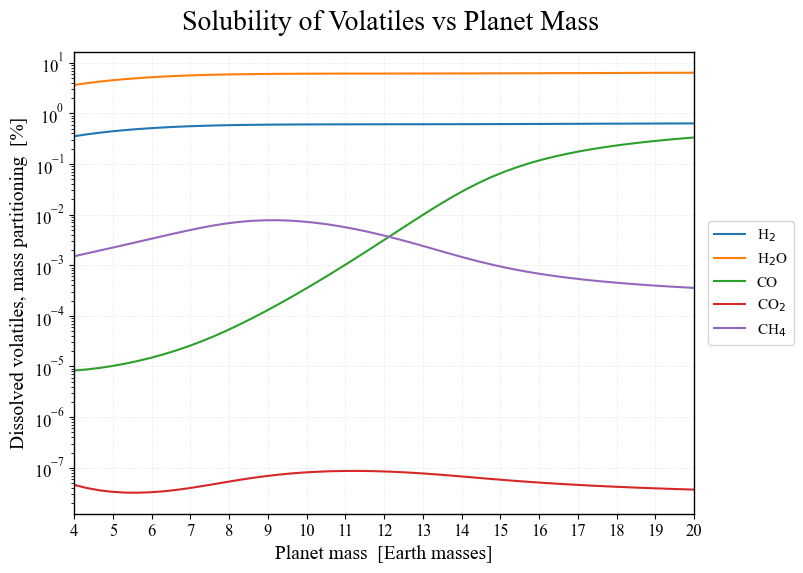

In [277]:
# ===========================================================
# FIGURE 1 — Solubility of species vs mass
# ===========================================================
set_master_nature_style()
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(planet_mass_Earths, dissolved_wtpH2,  label="H$_2$")
ax.plot(planet_mass_Earths, dissolved_wtpH2O, label="H$_2$O")
ax.plot(planet_mass_Earths, dissolved_wtpCO,  label="CO")
ax.plot(planet_mass_Earths, dissolved_wtpCO2, label="CO$_2$")
ax.plot(planet_mass_Earths, dissolved_wtpCH4, label="CH$_4$")

set_x_ticks(ax)
apply_master_layout(fig, ax, "Solubility of Volatiles vs Planet Mass")
ax.set_xlabel("Planet mass  [Earth masses]")
ax.set_ylabel("Dissolved volatiles, mass partitioning  [%]")

plt.show()



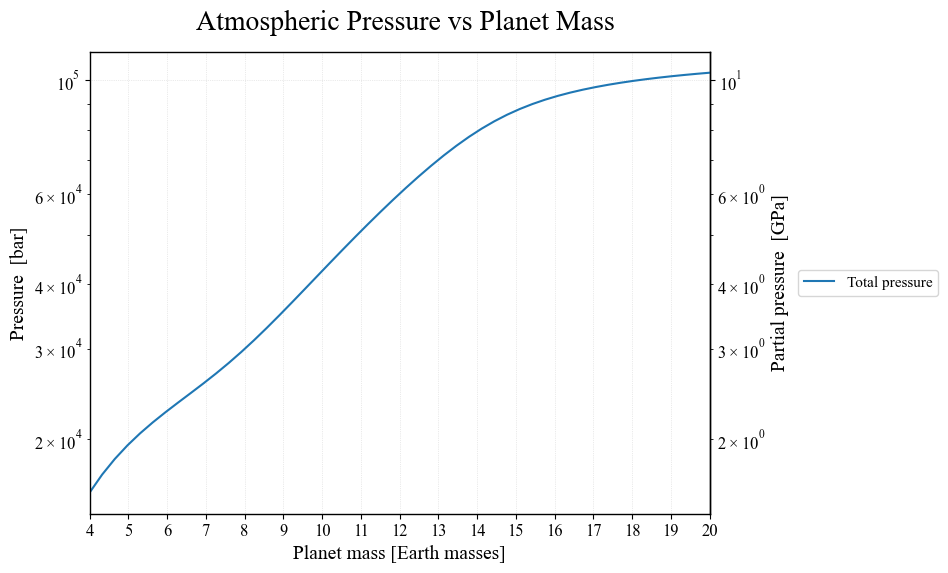

In [270]:
# ===========================================================
# FIGURE 2 — Atmospheric pressure vs mass
# ===========================================================
set_master_nature_style()
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(planet_mass_Earths, pressure, label="Total pressure")

set_x_ticks(ax)
apply_secondary_gpa_axis(ax)
set_x_ticks(ax)
ax.set_yscale("log")
ax.yaxis.set_major_locator(ticker.LogLocator(base=10))
ax.yaxis.set_major_formatter(ticker.LogFormatterMathtext())
fig.suptitle("Atmospheric Pressure vs Planet Mass", fontsize=20, ha="center", x=0.52, y=0.95)
ax.legend(
    frameon=True,
    loc="center left",
    bbox_to_anchor=(1.13, 0.5)
)
ax.set_xlabel("Planet mass [Earth masses]")
ax.set_ylabel("Pressure  [bar]")

plt.show()



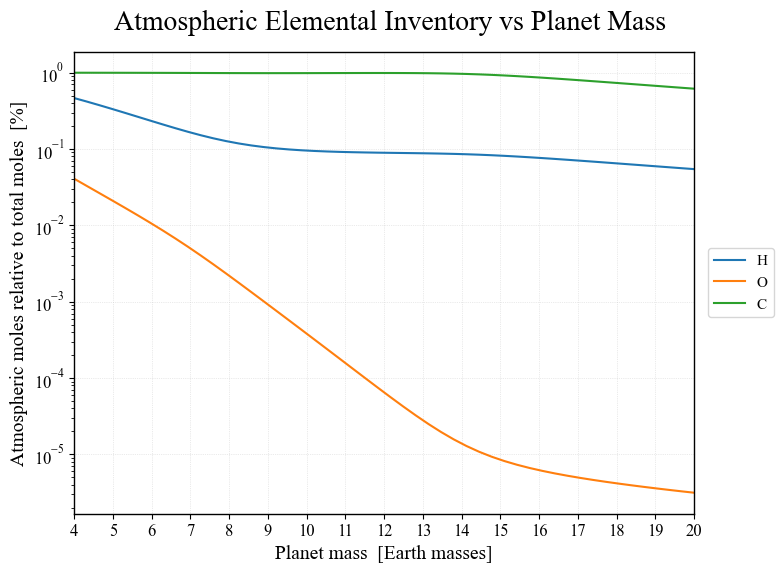

In [273]:
# ===========================================================
# FIGURE 3 — Elemental atmospheric abundances vs mass
# ===========================================================
set_master_nature_style()
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(planet_mass_Earths, element_H, label="H")
ax.plot(planet_mass_Earths, element_O, label="O")
ax.plot(planet_mass_Earths, element_C, label="C")
ax.plot(planet_mass_Earths, element_N, label="N")
set_x_ticks(ax)
apply_master_layout(fig, ax, "Atmospheric Elemental Inventory vs Planet Mass")
ax.set_xlabel("Planet mass  [Earth masses]")
ax.set_ylabel("Atmospheric moles relative to total moles  [%]")

plt.show()

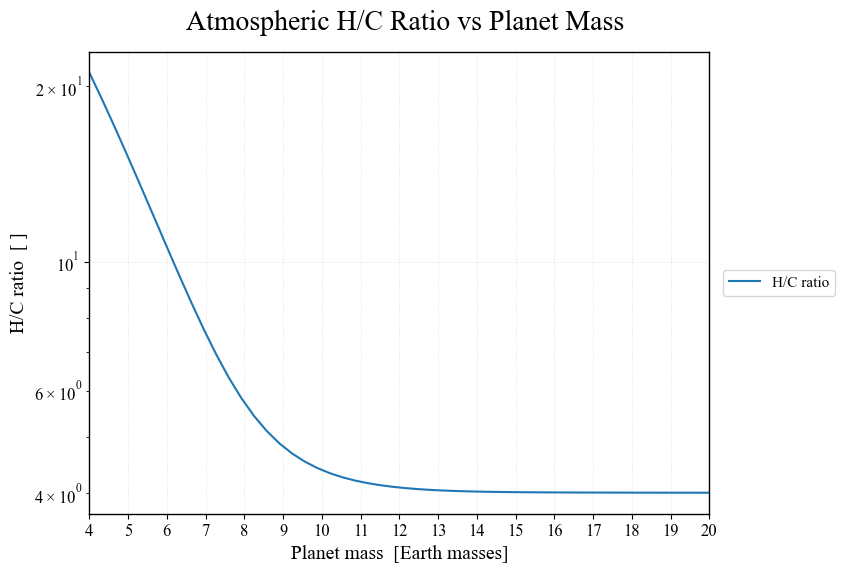

In [276]:
# ===========================================================
# FIGURE 4 — H/C ratio vs mass
# ===========================================================
set_master_nature_style()
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(planet_mass_Earths, ratio_H_C, label="H/C ratio")
set_x_ticks(ax)
apply_master_layout(fig, ax, "Atmospheric H/C Ratio vs Planet Mass")
ax.set_xlabel("Planet mass  [Earth masses]")
ax.set_ylabel("H/C ratio  [ ]")

plt.show()

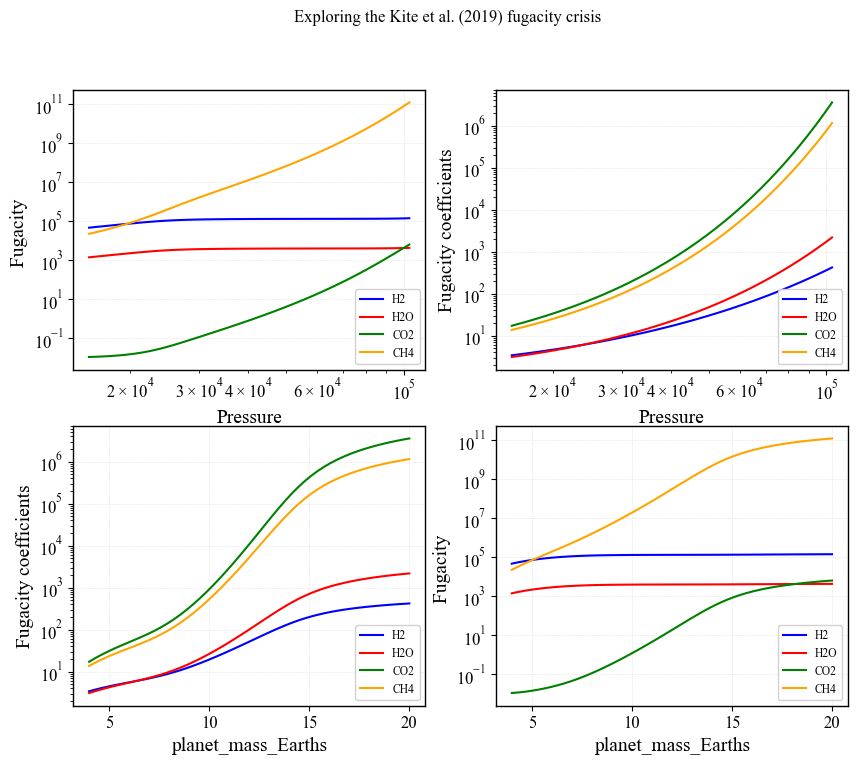

In [275]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

ax = axes[0, 0]
ax.plot(pressure, fugacityH2, label='H2', color='blue')
ax.plot(pressure, fugacityH2O, label='H2O', color='red')
ax.plot(pressure, fugacityCO2, label='CO2', color='green')
ax.plot(pressure, fugacityCH4, label='CH4', color='orange')
ax.set_yscale("log")
ax.set_xscale("log")
ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"Pressure")
ax.set_ylabel("Fugacity ")


ax = axes[0, 1]
ax.plot(pressure, fugacity_coefficientH2, label='H2', color='blue')
ax.plot(pressure, fugacity_coefficientH2O, label='H2O', color='red')
ax.plot(pressure, fugacity_coefficientCO2, label='CO2', color='green')
ax.plot(pressure, fugacity_coefficientCH4, label='CH4', color='orange')
ax.set_yscale("log")
ax.set_xscale("log")

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"Pressure")
ax.set_ylabel("Fugacity coefficients")

ax = axes[1, 1]
ax.plot(planet_mass_Earths, fugacityH2, label='H2', color='blue')
ax.plot(planet_mass_Earths, fugacityH2O, label='H2O', color='red')
ax.plot(planet_mass_Earths, fugacityCO2, label='CO2', color='green')
ax.plot(planet_mass_Earths, fugacityCH4, label='CH4', color='orange')
ax.set_yscale("log")

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass_Earths")
ax.set_ylabel("Fugacity ")

ax = axes[1, 0]
ax.plot(planet_mass_Earths, fugacity_coefficientH2, label='H2', color='blue')
ax.plot(planet_mass_Earths, fugacity_coefficientH2O, label='H2O', color='red')
ax.plot(planet_mass_Earths, fugacity_coefficientCO2, label='CO2', color='green')
ax.plot(planet_mass_Earths, fugacity_coefficientCH4, label='CH4', color='orange')
ax.set_yscale("log")

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"planet_mass_Earths")
ax.set_ylabel("Fugacity coefficients")


fig.suptitle("Exploring the Kite et al. (2019) fugacity crisis")

plt.show()

## Surface temparature

Planet mass varies from 4 to 9 MEarth, surface radius is fixed at 1.76 REarth

In [161]:

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25 
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

temps =  np.linspace(2500, 3500, number_of_realisations)

# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(
    number_of_realisations, 0
)  # ~3% of planet mass, used for fix Surf Radius and Planet Mass cases
log10_ch_ratios = np.full(number_of_realisations, -0.58)  # 100X Solar
fO2_log10_shifts = np.full(number_of_realisations, -3)

h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}

In [111]:
sub_neptune = Planet(
    surface_temperature=temps,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [112]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyMp_withsol = InteriorAtmosphere(idealspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
output_ideal_varyMp_withsol = model_ideal_varyMp_withsol.output

# Write the complete solution to Excel
output_ideal_varyMp_withsol.to_excel("A_FINAL_TEST_TEMP_IDEAL")

# Write the data to a pickle file with dataframes
output_ideal_varyMp_withsol.to_pickle("A_FINAL_TEST_TEMP_IDEAL")

[14:26:45 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13')
[14:26:45 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:26:45 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[14:26:45 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[14:26:45 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[14:26:45 - atmodeller.classes             - INFO     ] - Solver steps (max) = 38
[14:26:45 - atmodeller.output              - INFO     ] - Writing output to excel
[14:26:45 - a

In [113]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_real_varyMp_withsol = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}

model_real_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
    # Use the ideal solution for the initial guess of the real case
    initial_log_number_density=output_ideal_varyMp_withsol.log_number_density,
)
A_FINAL_TEST_TEMP_REAL = model_real_varyMp_withsol.output

# Write the complete solution to Excel
A_FINAL_TEST_TEMP_REAL.to_excel("A_FINAL_TEST_TEMP_REAL")

# Write the data to a pickle file with dataframes
A_FINAL_TEST_TEMP_REAL.to_pickle("A_FINAL_TEST_TEMP_REAL")

[14:26:46 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[14:26:46 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:26:46 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[14:26:46 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)
[14:26:46 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[14:26:46 - atmodeller.classes             - INFO     ] - Solver steps (max) = 14
[14:26:46 - atmodeller.output              - INFO    

In [169]:

output_df = A_FINAL_TEST_TEMP_REAL.to_dataframes()

pressure = output_df["atmosphere"]["pressure"]
pressure_GPa = pressure * 1e-4

fugacity_coefficientH2 = output_df["H2_g"]["fugacity_coefficient"]
fugacity_coefficientH2O = output_df["H2O_g"]["fugacity_coefficient"]
fugacity_coefficientCO2 = output_df["CO2_g"]["fugacity_coefficient"]
fugacity_coefficientCH4 = output_df["CH4_g"]["fugacity_coefficient"]

fugacityH2 = output_df["H2_g"]["fugacity"]
fugacityH2O = output_df["H2O_g"]["fugacity"]
fugacityCO2 = output_df["CO2_g"]["fugacity"]
fugacityCH4 = output_df["CH4_g"]["fugacity"]



dissolved_ppmwH2 = output_df["H2_g"]["dissolved_ppmw"]
dissolved_wtpH2 = dissolved_ppmwH2 * 1e-4  # wt.%

dissolved_ppmwH2O = output_df["H2O_g"]["dissolved_ppmw"]
dissolved_wtpH2O = dissolved_ppmwH2O * 1e-4  # wt.%

dissolved_ppmwCO2 = output_df["CO2_g"]["dissolved_ppmw"]
dissolved_wtpCO2 = dissolved_ppmwCO2 * 1e-4  # wt.%

dissolved_ppmwCH4 = output_df["CH4_g"]["dissolved_ppmw"]
dissolved_wtpCH4 = dissolved_ppmwCH4 * 1e-4  # wt.%


molesCH4 = output_df["CH4_g"]["atmosphere_moles"] / output_df["CH4_g"]["total_moles"]


H2_1 = fugacityH2[0]
H2_2 = fugacityH2[49]

H2O_1 = fugacityH2O[0]
H2O_2 = fugacityH2O[49]

CO2_1 = fugacityCO2[0]
CO2_2 = fugacityCO2[49]

CH4_1 = fugacityCH4[0]
CH4_2 = fugacityCH4[49]

K_1 = (CH4_1 * H2O_1**2) / (CO2_1 * H2_1**4)
K_2 = (CH4_2 * H2O_2**2) / (CO2_2 * H2_2**4)

print(K_1 - K_2)


2.1484111965611936e-08


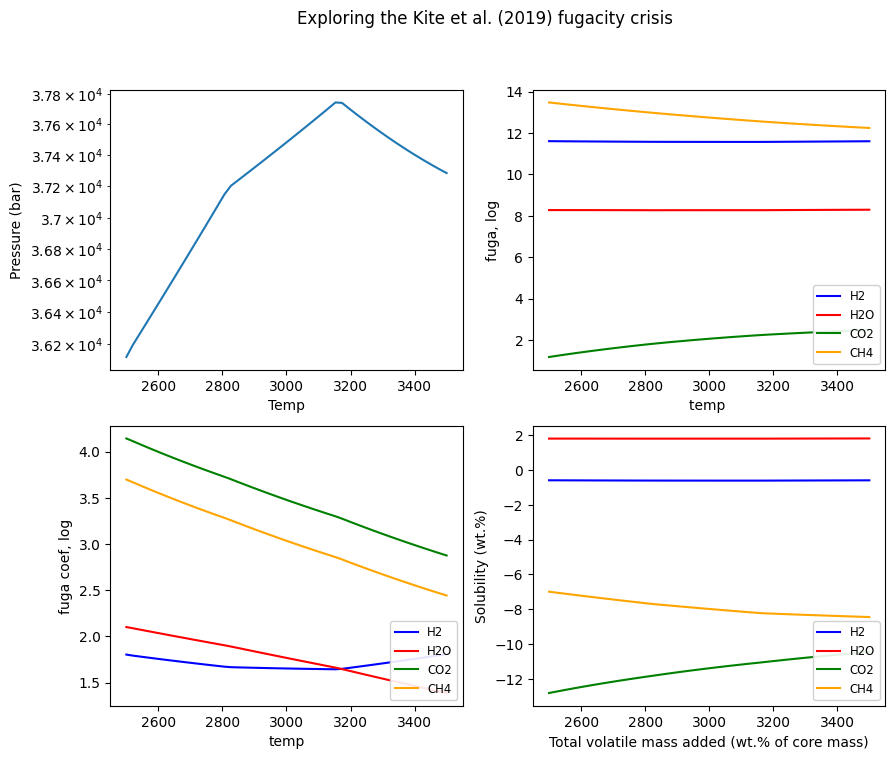

In [164]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

ax = axes[0, 0]
ax.plot(temps, pressure)
ax.set_yscale("log")
ax.set_xlabel(r"Temp")
ax.set_ylabel("Pressure (bar)")

ax = axes[1, 0]
ax.plot(temps, np.log(fugacity_coefficientH2), label='H2', color='blue')
ax.plot(temps, np.log(fugacity_coefficientH2O), label='H2O', color='red')
ax.plot(temps, np.log(fugacity_coefficientCO2), label='CO2', color='green')
ax.plot(temps, np.log(fugacity_coefficientCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel("temp")
ax.set_ylabel("fuga coef, log")

ax = axes[1, 1]
# Plot solubility as wt.%
ax.plot(temps, np.log(dissolved_wtpH2), label='H2', color='blue')
ax.plot(temps, np.log(dissolved_wtpH2O), label='H2O', color='red')
ax.plot(temps, np.log(dissolved_wtpCO2), label='CO2', color='green')
ax.plot(temps, np.log(dissolved_wtpCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel(r"Total volatile mass added (wt.% of core mass)")
ax.set_ylabel("Solubility (wt.%)")

ax = axes[0, 1]
ax.plot(temps, np.log(fugacityH2), label='H2', color='blue')
ax.plot(temps, np.log(fugacityH2O), label='H2O', color='red')
ax.plot(temps, np.log(fugacityCO2), label='CO2', color='green')
ax.plot(temps, np.log(fugacityCH4), label='CH4', color='orange')

ax.legend(loc='lower right', fontsize='small', framealpha=0.9)
ax.set_xlabel("temp ")
ax.set_ylabel("fuga, log")


fig.suptitle("Exploring the Kite et al. (2019) fugacity crisis")

plt.show()